In [3]:
import sys

print(sys.executable)

c:\CricIQ\venv\Scripts\python.exe


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import json
import zipfile
from pathlib import Path

print("CricketIQ Environment Ready!")

CricketIQ Environment Ready!


In [5]:
PROJECT_ROOT = Path(r"C:\CricIQ")

CRICSHEET_ZIP = PROJECT_ROOT / "data" / "raw" / "cricsheet_json" / "odis_json.zip"

MENDELEY_FOLDER = PROJECT_ROOT / "data" / "raw" / "mendeley"

In [6]:
with zipfile.ZipFile(CRICSHEET_ZIP, "r") as archive:

    json_files = [
        file for file in archive.namelist()
        if file.lower().endswith(".json")
    ]

print("Total JSON files:", len(json_files))
print("First 5 files:", json_files[:5])

Total JSON files: 3226
First 5 files: ['1000887.json', '1000889.json', '1000891.json', '1000893.json', '1000895.json']


In [7]:
with zipfile.ZipFile(CRICSHEET_ZIP, "r") as archive:

    sample_file = json_files[0]

    with archive.open(sample_file) as file:
        match_data = json.load(file)

print("Loaded file:", sample_file)
print("Data type:", type(match_data))
print("Top-level keys:", match_data.keys())

Loaded file: 1000887.json
Data type: <class 'dict'>
Top-level keys: dict_keys(['meta', 'info', 'innings'])


In [8]:
match_info = match_data["info"]

print("Teams:", match_info["teams"])
print("Date:", match_info["dates"])
print("Venue:", match_info.get("venue"))
print("City:", match_info.get("city"))
print("Toss:", match_info.get("toss"))
print("Outcome:", match_info.get("outcome"))

Teams: ['Australia', 'Pakistan']
Date: ['2017-01-13']
Venue: Brisbane Cricket Ground, Woolloongabba
City: Brisbane
Toss: {'decision': 'bat', 'winner': 'Australia'}
Outcome: {'by': {'runs': 92}, 'winner': 'Australia'}


In [9]:
print(f'Number of innings : {(len(match_data["innings"]))}')

for innings in match_data["innings"]:
    
    print(f'\nBatting Team : {innings["team"]}')
    print("Number of overs : ", len(innings["overs"]))

Number of innings : 2

Batting Team : Australia
Number of overs :  50

Batting Team : Pakistan
Number of overs :  43


In [10]:
for innings in match_data["innings"]:

    print("\nBatting team:", innings["team"])

    first_10_overs = innings["overs"][:10]

    for over in first_10_overs:

        print(f"\nOver: {over['over'] + 1}")

        for delivery in over["deliveries"]:

            print(f'Batsman: {delivery["batter"]}')

    print("\nTotal overs:", len(innings["overs"]))


Batting team: Australia

Over: 1
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner

Over: 2
Batsman: TM Head
Batsman: TM Head
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner

Over: 3
Batsman: TM Head
Batsman: DA Warner
Batsman: DA Warner
Batsman: TM Head
Batsman: DA Warner
Batsman: DA Warner

Over: 4
Batsman: TM Head
Batsman: TM Head
Batsman: TM Head
Batsman: DA Warner
Batsman: DA Warner
Batsman: TM Head

Over: 5
Batsman: DA Warner
Batsman: TM Head
Batsman: DA Warner
Batsman: SPD Smith
Batsman: CA Lynn
Batsman: CA Lynn

Over: 6
Batsman: TM Head
Batsman: CA Lynn
Batsman: TM Head
Batsman: CA Lynn
Batsman: CA Lynn
Batsman: CA Lynn
Batsman: CA Lynn

Over: 7
Batsman: TM Head
Batsman: TM Head
Batsman: TM Head
Batsman: CA Lynn
Batsman: TM Head
Batsman: TM Head

Over: 8
Batsman: CA Lynn
Batsman: CA Lynn
Batsman: TM Head
Batsman: TM Head
Batsman: TM Head
Batsman: TM Head

Over: 9
Bats

In [11]:
print("Number of deliveries in 10th over:")

for innings in match_data["innings"]:
    print(
        innings["team"],
        len(innings["overs"][9]["deliveries"])
    )

Number of deliveries in 10th over:
Australia 6
Pakistan 7


In [12]:
for innings in match_data["innings"]:

    print("\nBatting team:", innings["team"])

    first_10_overs = innings["overs"][:10]

    for over in first_10_overs:

        print(f"\nOver: {over['over'] + 1}")

        for delivery in over["deliveries"]:

            print(f'Batsman: {delivery["batter"]}')

    print("\nTotal overs:", len(innings["overs"]))


Batting team: Australia

Over: 1
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner

Over: 2
Batsman: TM Head
Batsman: TM Head
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner
Batsman: DA Warner

Over: 3
Batsman: TM Head
Batsman: DA Warner
Batsman: DA Warner
Batsman: TM Head
Batsman: DA Warner
Batsman: DA Warner

Over: 4
Batsman: TM Head
Batsman: TM Head
Batsman: TM Head
Batsman: DA Warner
Batsman: DA Warner
Batsman: TM Head

Over: 5
Batsman: DA Warner
Batsman: TM Head
Batsman: DA Warner
Batsman: SPD Smith
Batsman: CA Lynn
Batsman: CA Lynn

Over: 6
Batsman: TM Head
Batsman: CA Lynn
Batsman: TM Head
Batsman: CA Lynn
Batsman: CA Lynn
Batsman: CA Lynn
Batsman: CA Lynn

Over: 7
Batsman: TM Head
Batsman: TM Head
Batsman: TM Head
Batsman: CA Lynn
Batsman: TM Head
Batsman: TM Head

Over: 8
Batsman: CA Lynn
Batsman: CA Lynn
Batsman: TM Head
Batsman: TM Head
Batsman: TM Head
Batsman: TM Head

Over: 9
Bats

In [13]:
def keys(match_data):
    info = match_data["info"]
    match_keys = info.keys()
    str1 = ""
    for key in match_keys:
        str1 += f"\n{key}"
    return str1
print(keys(match_data))


balls_per_over
city
dates
event
gender
match_type
match_type_number
officials
outcome
overs
player_of_match
players
registry
season
team_type
teams
toss
venue


In [14]:
def extract_match_info(match_data):

    info = match_data["info"]

    teams = info["teams"]
    outcome = info.get("outcome", {})
    toss = info.get("toss", {})

    match = {

        "date": info["dates"][0],

        "team1": teams[0],
        "team2": teams[1],

        "venue": info.get("venue"),
        "city": info.get("city"),

        "toss_winner": toss.get("winner"),
        "toss_decision": toss.get("decision"),

        "winner": outcome.get("winner"),

        "overs": info.get("overs"),

        "gender": info.get("gender"),

        "match_type": info.get("match_type")

    }

    return match

In [15]:
sample_match = extract_match_info(match_data)

print(sample_match)

{'date': '2017-01-13', 'team1': 'Australia', 'team2': 'Pakistan', 'venue': 'Brisbane Cricket Ground, Woolloongabba', 'city': 'Brisbane', 'toss_winner': 'Australia', 'toss_decision': 'bat', 'winner': 'Australia', 'overs': 50, 'gender': 'male', 'match_type': 'ODI'}


In [16]:
matches = []

with zipfile.ZipFile(CRICSHEET_ZIP, "r") as archive:

    for file_name in json_files:

        with archive.open(file_name) as file:

            match_data = json.load(file)

            match_info = extract_match_info(match_data)

            matches.append(match_info)

matches_df = pd.DataFrame(matches)

print("Total matches:", len(matches_df))

matches_df.head()

Total matches: 3226


,date,team1,team2,venue,city,toss_winner,toss_decision,winner,overs,gender,match_type
0,2017-01-13,Australia,Pakistan,"Brisbane Cricket Ground, Woolloongabba",Brisbane,Australia,bat,Australia,50,male,ODI
1,2017-01-15,Australia,Pakistan,Melbourne Cricket Ground,None,Australia,bat,Pakistan,50,male,ODI
2,2017-01-19,Australia,Pakistan,Western Australia Cricket Association Ground,Perth,Australia,field,Australia,50,male,ODI
3,2017-01-22,Australia,Pakistan,Sydney Cricket Ground,None,Australia,bat,Australia,50,male,ODI
4,2017-01-26,Australia,Pakistan,Adelaide Oval,None,Australia,bat,Australia,50,male,ODI


In [17]:
matches_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3226 entries, 0 to 3225
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   date           3226 non-null   object
 1   team1          3226 non-null   object
 2   team2          3226 non-null   object
 3   venue          3226 non-null   object
 4   city           2920 non-null   object
 5   toss_winner    3226 non-null   object
 6   toss_decision  3226 non-null   object
 7   winner         3070 non-null   object
 8   overs          3226 non-null   int64 
 9   gender         3226 non-null   object
 10  match_type     3226 non-null   object
dtypes: int64(1), object(10)
memory usage: 277.4+ KB


In [18]:
matches_df.describe(include = "all")

,date,team1,team2,venue,city,toss_winner,toss_decision,winner,overs,gender,match_type
count,3226,3226,3226,3226,2920,3226,3226,3070,3226.0,3226,3226
unique,2624,26,27,387,174,27,2,27,NaN,2,1
top,2017-07-02,India,Pakistan,Harare Sports Club,Colombo,Australia,field,Australia,NaN,male,ODI
freq,6,344,338,133,138,319,1663,408,NaN,2607,3226
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN


In [19]:
matches_df.isnull().sum()

date               0
team1              0
team2              0
venue              0
city             306
toss_winner        0
toss_decision      0
winner           156
overs              0
gender             0
match_type         0
dtype: int64

In [20]:
matches_df["gender"].value_counts()

gender
male      2607
female     619
Name: count, dtype: int64

In [21]:
matches_df["gender"].value_counts(normalize=True) * 100

gender
male      80.812151
female    19.187849
Name: proportion, dtype: float64

In [22]:
missing_winner_percentage = (
    matches_df["winner"].isnull().mean() * 100
)

print(f"Matches without winner: {missing_winner_percentage:.2f}%")

Matches without winner: 4.84%


In [23]:
matches_df["date"] = pd.to_datetime(matches_df["date"])

print("Earliest match:", matches_df["date"].min())
print("Latest match:", matches_df["date"].max())

Earliest match: 2002-06-27 00:00:00
Latest match: 2026-10-25 00:00:00


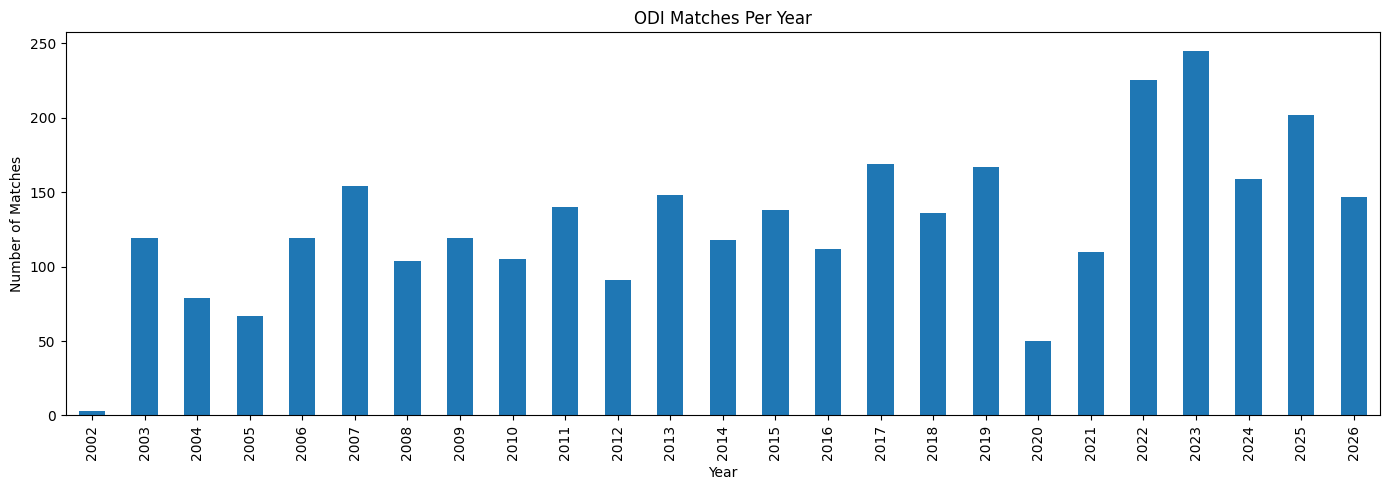

In [24]:
matches_df["year"] = matches_df["date"].dt.year

matches_per_year = matches_df["year"].value_counts().sort_index()

plt.figure(figsize=(14, 5))

matches_per_year.plot(kind="bar")

plt.title("ODI Matches Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Matches")

plt.tight_layout()
plt.show()

In [25]:
### 2.4 Investigating match outcomes

matches_df["winner"].value_counts(dropna=False)

winner
Australia                   408
India                       390
South Africa                320
England                     319
New Zealand                 261
Sri Lanka                   256
Pakistan                    251
West Indies                 182
None                        156
Bangladesh                  149
Zimbabwe                     75
Scotland                     70
Ireland                      67
Nepal                        47
United States of America     47
United Arab Emirates         45
Netherlands                  40
Namibia                      37
Oman                         35
Canada                       21
Papua New Guinea             14
Kenya                        13
Thailand                     11
Hong Kong                     5
Asia XI                       3
Bermuda                       2
Jersey                        1
Africa XI                     1
Name: count, dtype: int64

In [26]:
outcome_details = []

with zipfile.ZipFile(CRICSHEET_ZIP, "r") as archive:

    for file_name in json_files:

        with archive.open(file_name) as file:

            data = json.load(file)

            outcome = data["info"].get("outcome", {})

            if not outcome.get("winner"):

                outcome_details.append({
                    "date": data["info"]["dates"][0],
                    "teams": data["info"]["teams"],
                    "venue": data["info"].get("venue"),
                    "outcome": outcome
                })

outcome_df = pd.DataFrame(outcome_details)

print("Matches without a winner:", len(outcome_df))

outcome_df.head(10)

Matches without a winner: 156


,date,teams,venue,outcome
0,2016-09-08,"[Scotland, Hong Kong]","Grange Cricket Club Ground, Raeburn Place",{'result': 'no result'}
1,2017-06-02,"[Australia, New Zealand]",Edgbaston,{'result': 'no result'}
2,2017-06-05,"[Australia, Bangladesh]",Kennington Oval,{'result': 'no result'}
3,2017-09-21,"[England, West Indies]",Trent Bridge,{'result': 'no result'}
4,2017-05-12,"[Ireland, Bangladesh]",Malahide,{'result': 'no result'}
5,2016-11-19,"[Zimbabwe, West Indies]",Queens Sports Club,{'result': 'tie'}
6,2016-11-21,"[Zimbabwe, Sri Lanka]",Queens Sports Club,{'result': 'no result'}
7,2017-03-28,"[Sri Lanka, Bangladesh]",Rangiri Dambulla International Stadium,{'result': 'no result'}
8,2017-06-23,"[West Indies, India]","Queen's Park Oval, Port of Spain",{'result': 'no result'}
9,2018-03-12,"[Zimbabwe, Scotland]",Queens Sports Club,{'result': 'tie'}


In [27]:
men_df = matches_df[
    matches_df["gender"] == "male"
].copy()

print("Men's ODI matches:", len(men_df))

Men's ODI matches: 2607


In [28]:
outcome_df["result_type"] = outcome_df["outcome"].apply(
    lambda x: x.get("result", "other")
)

outcome_df["result_type"].value_counts()

result_type
no result    122
tie           34
Name: count, dtype: int64

In [29]:
men_df["winner"].value_counts(dropna=False)

winner
India                       315
Australia                   298
South Africa                232
Sri Lanka                   229
England                     225
Pakistan                    216
New Zealand                 212
West Indies                 145
Bangladesh                  133
None                        130
Zimbabwe                     65
Scotland                     61
Ireland                      49
Nepal                        47
United States of America     44
United Arab Emirates         41
Namibia                      37
Netherlands                  36
Oman                         35
Canada                       21
Kenya                        13
Papua New Guinea             11
Hong Kong                     5
Asia XI                       3
Bermuda                       2
Jersey                        1
Africa XI                     1
Name: count, dtype: int64

In [30]:
all_teams = sorted(
    set(men_df["team1"].unique()) |
    set(men_df["team2"].unique())
)

print("Total unique team names:", len(all_teams))

for team in all_teams:
    print(team)

Total unique team names: 27
Africa XI
Asia XI
Australia
Bangladesh
Bermuda
Canada
England
Hong Kong
ICC World XI
India
Ireland
Jersey
Kenya
Namibia
Nepal
Netherlands
New Zealand
Oman
Pakistan
Papua New Guinea
Scotland
South Africa
Sri Lanka
United Arab Emirates
United States of America
West Indies
Zimbabwe


In [31]:
men_df["winner"].value_counts(dropna=False)


winner
India                       315
Australia                   298
South Africa                232
Sri Lanka                   229
England                     225
Pakistan                    216
New Zealand                 212
West Indies                 145
Bangladesh                  133
None                        130
Zimbabwe                     65
Scotland                     61
Ireland                      49
Nepal                        47
United States of America     44
United Arab Emirates         41
Namibia                      37
Netherlands                  36
Oman                         35
Canada                       21
Kenya                        13
Papua New Guinea             11
Hong Kong                     5
Asia XI                       3
Bermuda                       2
Jersey                        1
Africa XI                     1
Name: count, dtype: int64

In [32]:
print(
    "Afghanistan present:",
    any("afghanistan" in team.lower() for team in all_teams)
)

Afghanistan present: False


In [33]:
pd.crosstab(
    matches_df["gender"],
    matches_df["winner"].isnull(),
    margins=True
)

winner,False,True,All
gender,,,
female,593,26,619
male,2477,130,2607
All,3070,156,3226


In [34]:
print("Team 1 values:")
print(sorted(men_df["team1"].unique()))

print("\nTeam 2 values:")
print(sorted(men_df["team2"].unique()))

Team 1 values:
['Africa XI', 'Australia', 'Bangladesh', 'Bermuda', 'Canada', 'England', 'Hong Kong', 'India', 'Ireland', 'Jersey', 'Kenya', 'Namibia', 'Nepal', 'Netherlands', 'New Zealand', 'Oman', 'Pakistan', 'Papua New Guinea', 'Scotland', 'South Africa', 'Sri Lanka', 'United Arab Emirates', 'United States of America', 'West Indies', 'Zimbabwe']

Team 2 values:
['Asia XI', 'Australia', 'Bangladesh', 'Bermuda', 'Canada', 'England', 'Hong Kong', 'ICC World XI', 'India', 'Ireland', 'Jersey', 'Kenya', 'Namibia', 'Nepal', 'Netherlands', 'New Zealand', 'Oman', 'Pakistan', 'Papua New Guinea', 'Scotland', 'South Africa', 'Sri Lanka', 'United Arab Emirates', 'United States of America', 'West Indies', 'Zimbabwe']


In [35]:
### 3.1 Unique team analysis.

In [36]:
all_teams = sorted(
    set(men_df["team1"].unique()) |
    set(men_df["team2"].unique())
)

print("Total unique teams:", len(all_teams))

for team in all_teams:
    print(team)

Total unique teams: 27
Africa XI
Asia XI
Australia
Bangladesh
Bermuda
Canada
England
Hong Kong
ICC World XI
India
Ireland
Jersey
Kenya
Namibia
Nepal
Netherlands
New Zealand
Oman
Pakistan
Papua New Guinea
Scotland
South Africa
Sri Lanka
United Arab Emirates
United States of America
West Indies
Zimbabwe


In [37]:
representative_teams = [
    "Africa XI",
    "Asia XI",
    "ICC World XI"
]

print("Representative teams:", representative_teams)

Representative teams: ['Africa XI', 'Asia XI', 'ICC World XI']


In [38]:
print(
    "Exact duplicate rows:",
    men_df.duplicated().sum()
)

Exact duplicate rows: 0


In [39]:
men_df["date"] = pd.to_datetime(men_df["date"])

In [40]:
men_df = men_df.sort_values(
    by="date"
).reset_index(drop=True)

In [41]:
print("Earliest matches:")
display(men_df.head(2))

print("Latest matches:")
display(men_df.tail(2))

Earliest matches:


,date,team1,team2,venue,city,toss_winner,toss_decision,winner,overs,gender,match_type,year
0,2002-06-27,England,Sri Lanka,"Trent Bridge, Nottingham",Nottingham,England,bat,England,50,male,ODI,2002
1,2002-06-29,England,India,"Lord's, London",London,England,bat,India,50,male,ODI,2002


Latest matches:


,date,team1,team2,venue,city,toss_winner,toss_decision,winner,overs,gender,match_type,year
2605,2026-10-25,England,Pakistan,"Gaddafi Stadium, Lahore",Lahore,Pakistan,field,Pakistan,50,male,ODI,2026
2606,2026-10-25,United Arab Emirates,Netherlands,"ICC Academy, Dubai",Dubai,United Arab Emirates,bat,Netherlands,50,male,ODI,2026


In [42]:
men_labeled_df = men_df[
    men_df["winner"].notna()
].copy()

print("All men's matches:", len(men_df))

print("Matches with known winners:", len(men_labeled_df))

print("Matches without winners:", men_df["winner"].isna().sum())

All men's matches: 2607
Matches with known winners: 2477
Matches without winners: 130


In [ ]:
men_labeled_df = men_labeled_df[
    ~men_labeled_df["team1"].isin(representative_teams) &
    ~men_labeled_df["team2"].isin(representative_teams)
].copy()

print("National-team training candidates:", len(men_labeled_df))

National-team training candidates: 2471


In [ ]:
print("Original dataset:")
print("Total matches:", len(matches_df))
print("Earliest date:", matches_df["date"].min())
print("Latest date:", matches_df["date"].max())

Original dataset:
Total matches: 3226
Earliest date: 2002-06-27 00:00:00
Latest date: 2026-10-25 00:00:00


In [ ]:
print("\nMen's dataset:")
print("Total matches:", len(men_df))
print("Earliest date:", men_df["date"].min())
print("Latest date:", men_df["date"].max())


Men's dataset:
Total matches: 2607
Earliest date: 2002-06-27 00:00:00
Latest date: 2026-10-25 00:00:00


In [ ]:
men_df = men_df.sort_values(
    by="date",
    ascending=True
).reset_index(drop=True)

In [ ]:
print("First 5 men's ODI matches:")
display(men_labeled_df[["date", "team1", "team2", "winner"]].head())

print("\nLast 5 men's ODI matches:")
display(men_df[["date", "team1", "team2", "winner"]].tail())

First 5 men's ODI matches:


,date,team1,team2,winner
0,2002-06-27,England,Sri Lanka,England
1,2002-06-29,England,India,India
2,2002-12-29,New Zealand,India,New Zealand
3,2003-01-01,India,New Zealand,New Zealand
4,2003-01-04,India,New Zealand,New Zealand



Last 5 men's ODI matches:


,date,team1,team2,winner
2602,2026-10-22,Ireland,Namibia,Ireland
2603,2026-10-22,England,Sri Lanka,Sri Lanka
2604,2026-10-24,Namibia,Ireland,Namibia
2605,2026-10-25,England,Pakistan,Pakistan
2606,2026-10-25,United Arab Emirates,Netherlands,Netherlands


In [ ]:
print(
    men_df["date"].dt.year.value_counts().sort_index()
)

date
2002      3
2003    119
2004     79
2005     67
2006    119
2007    151
2008     99
2009    116
2010    105
2011    137
2012     84
2013    124
2014    104
2015    127
2016     85
2017    107
2018    105
2019    127
2020     44
2021     65
2022    148
2023    195
2024     89
2025    108
2026    100
Name: count, dtype: int64


In [ ]:
men_labeled_df = men_df[
    men_df["winner"].notna()
].copy()

men_labeled_df = men_labeled_df[
    ~men_labeled_df["team1"].isin(representative_teams) &
    ~men_labeled_df["team2"].isin(representative_teams)
].copy()

men_labeled_df = men_labeled_df.sort_values(
    by="date",
    ascending=True
).reset_index(drop=True)

In [ ]:
print("Men's dataset:")
print(men_df["date"].min(), "to", men_df["date"].max())

print("\nTraining candidates:")
print(
    men_labeled_df["date"].min(),
    "to",
    men_labeled_df["date"].max()
)

Men's dataset:
2002-06-27 00:00:00 to 2026-10-25 00:00:00

Training candidates:
2002-06-27 00:00:00 to 2026-10-25 00:00:00


In [ ]:
teams = sorted(
    set(men_labeled_df["team1"].unique()) |
    set(men_labeled_df["team2"].unique())
)

team_stats = []

for team in teams:

    matches_played = (
        (men_labeled_df["team1"] == team) |
        (men_labeled_df["team2"] == team)
    ).sum()

    wins = (men_labeled_df["winner"] == team).sum()

    losses = matches_played - wins

    win_percentage = (wins / matches_played) * 100

    team_stats.append({
        "team": team,
        "matches_played": matches_played,
        "wins": wins,
        "losses": losses,
        "win_percentage": win_percentage
    })

team_stats_df = pd.DataFrame(team_stats)

team_stats_df.head()

,team,matches_played,wins,losses,win_percentage
0,Australia,457,296,161,64.770241
1,Bangladesh,324,133,191,41.049383
2,Bermuda,12,2,10,16.666667
3,Canada,69,21,48,30.434783
4,England,426,225,201,52.816901


In [ ]:
team_stats = []

for team in teams:

    team_matches = men_df[
        (men_df["team1"] == team) |
        (men_df["team2"] == team)
    ]

    matches_played = len(team_matches)

    wins = (team_matches["winner"] == team).sum()

    ties = team_matches[
        team_matches["winner"].isna()
    ].shape[0]

    losses = (
        (team_matches["winner"].notna()) &
        (team_matches["winner"] != team)
    ).sum()

    no_results = 0
    # We will distinguish ties and no-results using
    # the original JSON outcome information in our next step.

    win_percentage = (wins / matches_played) * 100

    team_stats.append({
        "team": team,
        "matches_played": matches_played,
        "wins": wins,
        "losses": losses,
        "ties_or_no_results": ties,
        "win_percentage": win_percentage
    })

team_stats_df = pd.DataFrame(team_stats)

team_stats_df.head()

,team,matches_played,wins,losses,ties_or_no_results,win_percentage
0,Australia,482,298,161,23,61.825726
1,Bangladesh,334,133,191,10,39.820359
2,Bermuda,12,2,10,0,16.666667
3,Canada,72,21,48,3,29.166667
4,England,452,225,201,26,49.778761


In [ ]:
teams = sorted(
    set(men_labeled_df["team1"].unique()) |
    set(men_labeled_df["team2"].unique())
)

team_stats = []

for team in teams:

    matches_played = (
        (men_labeled_df["team1"] == team) |
        (men_labeled_df["team2"] == team)
    ).sum()

    wins = (men_labeled_df["winner"] == team).sum()

    losses = matches_played - wins

    win_percentage = (wins / matches_played) * 100

    team_stats.append({
        "team": team,
        "matches_played": matches_played,
        "wins": wins,
        "losses": losses,
        "win_percentage": round(win_percentage, 2)
    })

team_stats_df = pd.DataFrame(team_stats)

team_stats_df = team_stats_df.sort_values(
    by="win_percentage",
    ascending=False
).reset_index(drop=True)

team_stats_df

,team,matches_played,wins,losses,win_percentage
0,Australia,457,296,161,64.77
1,India,500,315,185,63.00
2,South Africa,377,232,145,61.54
3,New Zealand,374,212,162,56.68
4,United States of America,79,44,35,55.70
5,Scotland,112,61,51,54.46
6,England,426,225,201,52.82
7,Pakistan,409,216,193,52.81
8,Nepal,91,47,44,51.65
9,Sri Lanka,466,229,237,49.14


In [ ]:
#Afghanistan ODI Match Register.


In [ ]:
from pathlib import Path
import pandas as pd

REGISTER_DIR = Path(r"C:\CricIQ\data\raw\afghanistan_odi\match_register")
REGISTER_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "match_id",
    "date",
    "team1",
    "team2",
    "venue",
    "city",
    "tournament",
    "toss_winner",
    "toss_decision",
    "winner",
    "result_type",
    "result_margin",
    "source_primary",
    "source_secondary",
    "scorecard_status",
    "ball_by_ball_status",
    "verification_status",
    "notes"
]

register_df = pd.DataFrame(columns=columns)

register_path = REGISTER_DIR / "afghanistan_odi_match_register.csv"

register_df.to_csv(register_path, index=False)

print("Register created:", register_path)
print("Columns:", register_df.columns.tolist())

Register created: C:\CricIQ\data\raw\afghanistan_odi\match_register\afghanistan_odi_match_register.csv
Columns: ['match_id', 'date', 'team1', 'team2', 'venue', 'city', 'tournament', 'toss_winner', 'toss_decision', 'winner', 'result_type', 'result_margin', 'source_primary', 'source_secondary', 'scorecard_status', 'ball_by_ball_status', 'verification_status', 'notes']


In [ ]:
october_candidates = pd.DataFrame([
    {
        "date": "2026-10-19",
        "team1": "Afghanistan",
        "team2": "Zimbabwe",
        "winner": "Afghanistan",
        "result_type": "Win",
        "source_secondary": "SportsDB",
        "verification_status": "Needs scorecard verification"
    },
    {
        "date": "2026-10-21",
        "team1": "Bangladesh",
        "team2": "Afghanistan",
        "winner": "Afghanistan",
        "result_type": "Win",
        "source_secondary": "SportsDB",
        "verification_status": "Needs scorecard verification"
    },
    {
        "date": "2026-10-23",
        "team1": "Zimbabwe",
        "team2": "Afghanistan",
        "winner": "Afghanistan",
        "result_type": "Win",
        "source_secondary": "SportsDB",
        "verification_status": "Needs scorecard verification"
    }
])

october_candidates["date"] = pd.to_datetime(october_candidates["date"])

october_candidates

,date,team1,team2,winner,result_type,source_secondary,verification_status
0,2026-10-19,Afghanistan,Zimbabwe,Afghanistan,Win,SportsDB,Needs scorecard verification
1,2026-10-21,Bangladesh,Afghanistan,Afghanistan,Win,SportsDB,Needs scorecard verification
2,2026-10-23,Zimbabwe,Afghanistan,Afghanistan,Win,SportsDB,Needs scorecard verification


In [ ]:
october_verified = pd.DataFrame([
    {
        "date": "2026-10-19",
        "team1": "Afghanistan",
        "team2": "Zimbabwe",
        "venue": "Sheikh Zayed Stadium",
        "city": "Abu Dhabi",
        "tournament": "ODI Tri-Nation Series in UAE 2026",
        "toss_winner": "Afghanistan",
        "toss_decision": "bat",
        "winner": "Afghanistan",
        "result_type": "Win",
        "result_margin": "158 runs",
        "source_primary": "Cricbuzz",
        "source_secondary": "Moneycontrol",
        "scorecard_status": "Available",
        "ball_by_ball_status": "Not yet checked",
        "verification_status": "Cross-checked",
        "notes": "Afghanistan 294/10; Zimbabwe 136/10."
    },
    {
        "date": "2026-10-21",
        "team1": "Bangladesh",
        "team2": "Afghanistan",
        "venue": "Sharjah Cricket Stadium",
        "city": "Sharjah",
        "tournament": "ODI Tri-Nation Series in UAE 2026",
        "toss_winner": "Bangladesh",
        "toss_decision": "bat",
        "winner": "Afghanistan",
        "result_type": "Win",
        "result_margin": "7 wickets",
        "source_primary": "Cricbuzz",
        "source_secondary": "Moneycontrol",
        "scorecard_status": "Available",
        "ball_by_ball_status": "Not yet checked",
        "verification_status": "Cross-checked",
        "notes": "Bangladesh 160/10; Afghanistan 161/3."
    },
    {
        "date": "2026-10-23",
        "team1": "Zimbabwe",
        "team2": "Afghanistan",
        "venue": "Sharjah Cricket Stadium",
        "city": "Sharjah",
        "tournament": "ODI Tri-Nation Series in UAE 2026",
        "toss_winner": "Zimbabwe",
        "toss_decision": "bat",
        "winner": "Afghanistan",
        "result_type": "Win",
        "result_margin": "7 wickets",
        "source_primary": "ICC",
        "source_secondary": "Cricbuzz",
        "scorecard_status": "Available",
        "ball_by_ball_status": "Not yet checked",
        "verification_status": "Cross-checked",
        "notes": "Zimbabwe 169/10; Afghanistan 170/3."
    }
])

october_verified["date"] = pd.to_datetime(october_verified["date"])

october_verified

,date,team1,team2,venue,city,tournament,toss_winner,toss_decision,winner,result_type,result_margin,source_primary,source_secondary,scorecard_status,ball_by_ball_status,verification_status,notes
0,2026-10-19,Afghanistan,Zimbabwe,Sheikh Zayed Stadium,Abu Dhabi,ODI Tri-Nation Series in UAE 2026,Afghanistan,bat,Afghanistan,Win,158 runs,Cricbuzz,Moneycontrol,Available,Not yet checked,Cross-checked,Afghanistan 294/10; Zimbabwe 136/10.
1,2026-10-21,Bangladesh,Afghanistan,Sharjah Cricket Stadium,Sharjah,ODI Tri-Nation Series in UAE 2026,Bangladesh,bat,Afghanistan,Win,7 wickets,Cricbuzz,Moneycontrol,Available,Not yet checked,Cross-checked,Bangladesh 160/10; Afghanistan 161/3.
2,2026-10-23,Zimbabwe,Afghanistan,Sharjah Cricket Stadium,Sharjah,ODI Tri-Nation Series in UAE 2026,Zimbabwe,bat,Afghanistan,Win,7 wickets,ICC,Cricbuzz,Available,Not yet checked,Cross-checked,Zimbabwe 169/10; Afghanistan 170/3.


In [ ]:
register_df = pd.read_csv(register_path, parse_dates=["date"])

register_df = pd.concat(
    [register_df, october_verified],
    ignore_index=True
)

register_df = register_df.sort_values("date").reset_index(drop=True)

register_df.to_csv(register_path, index=False)

print("Saved:", register_path)
print("Total registered matches:", len(register_df))

Saved: C:\CricIQ\data\raw\afghanistan_odi\match_register\afghanistan_odi_match_register.csv
Total registered matches: 3


C:\Users\ASUS\AppData\Local\Temp\ipykernel_23112\1311364842.py:3: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  register_df = pd.concat(


In [ ]:
print("Duplicate dates and team combinations:")

duplicates = register_df.duplicated(
    subset=["date", "team1", "team2"],
    keep=False
)

print(register_df.loc[duplicates])

print("\nAfghanistan participation check:")

valid_teams = (
    register_df["team1"].eq("Afghanistan") |
    register_df["team2"].eq("Afghanistan")
)

print("All rows involve Afghanistan:", valid_teams.all())

Duplicate dates and team combinations:
Empty DataFrame
Columns: [match_id, date, team1, team2, venue, city, tournament, toss_winner, toss_decision, winner, result_type, result_margin, source_primary, source_secondary, scorecard_status, ball_by_ball_status, verification_status, notes]
Index: []

Afghanistan participation check:
All rows involve Afghanistan: True


In [ ]:
from pathlib import Path

project_path = Path(r"C:\CricIQ")

raw_path = project_path / "data" / "raw" / "cricsheet_json"
processed_path = project_path / "data" / "processed" / "cricsheet_odi"

# Create output directory
processed_path.mkdir(parents=True, exist_ok=True)

zip_path = raw_path / "odis_json.zip"

print("Raw data:", raw_path)
print("Processed data:", processed_path)
print("Output folder exists:", processed_path.exists())

Raw data: C:\CricIQ\data\raw\cricsheet_json
Processed data: C:\CricIQ\data\processed\cricsheet_odi
Output folder exists: True


In [ ]:
match_records = []

with zipfile.ZipFile(zip_path, "r") as zip_file:

    for filename in json_files:

        with zip_file.open(filename) as file:
            match = json.load(file)

        info = match["info"]
        outcome = info.get("outcome", {})
        result_by = outcome.get("by", {})

        match_records.append({
            "match_id": filename.replace(".json", ""),
            "date": info["dates"][0],
            "team_1": info["teams"][0],
            "team_2": info["teams"][1],
            "venue": info.get("venue"),
            "city": info.get("city"),
            "season": info.get("season"),
            "event": info.get("event", {}).get("name"),
            "toss_winner": info.get("toss", {}).get("winner"),
            "toss_decision": info.get("toss", {}).get("decision"),
            "winner": outcome.get("winner"),
            "win_by_runs": result_by.get("runs"),
            "win_by_wickets": result_by.get("wickets"),
            "gender": info.get("gender"),
            "match_type": info.get("match_type"),
            "team_type": info.get("team_type")
        })

cricsheet_matches_df = pd.DataFrame(match_records)

cricsheet_matches_df["date"] = pd.to_datetime(
    cricsheet_matches_df["date"]
)

# Keep men's international ODIs and exclude representative teams
representative_teams = ["Africa XI", "Asia XI", "ICC World XI"]

cricsheet_matches_df = cricsheet_matches_df[
    (cricsheet_matches_df["gender"] == "male") &
    (cricsheet_matches_df["team_type"] == "international") &
    (~cricsheet_matches_df["team_1"].isin(representative_teams)) &
    (~cricsheet_matches_df["team_2"].isin(representative_teams))
].copy()

cricsheet_matches_df.reset_index(drop=True, inplace=True)

print("Match-level dataset shape:", cricsheet_matches_df.shape)
display(cricsheet_matches_df.head())

NameError: name 'zipfile' is not defined

In [1]:

from pathlib import Path
import json

notebook_path = Path(
    r"C:\CricIQ\notebooks\01_data_exploration.ipynb"
)

if not notebook_path.exists():
    print("ERROR: Notebook file not found.")
else:
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])

    code_cells = [
        (i, cell) for i, cell in enumerate(cells)
        if cell.get("cell_type") == "code"
    ]

    markdown_cells = [
        (i, cell) for i, cell in enumerate(cells)
        if cell.get("cell_type") == "markdown"
    ]

    error_cells = []

    print("=" * 75)
    print("CRICKETIQ — NOTEBOOK 01 STRUCTURAL INSPECTION")
    print("=" * 75)

    print(f"\nTotal cells: {len(cells)}")
    print(f"Code cells: {len(code_cells)}")
    print(f"Markdown cells: {len(markdown_cells)}")

    print("\n" + "=" * 75)
    print("MARKDOWN SECTIONS")
    print("=" * 75)

    for i, cell in markdown_cells:
        source = "".join(cell.get("source", [])).strip()
        if source:
            print(f"\nCell {i}:")
            print(source[:500])

    print("\n" + "=" * 75)
    print("CODE CELL INVENTORY")
    print("=" * 75)

    for i, cell in code_cells:
        source = "".join(cell.get("source", [])).strip()
        first_line = source.splitlines()[0] if source else "[EMPTY CELL]"

        outputs = cell.get("outputs", [])
        errors = [
            output for output in outputs
            if output.get("output_type") == "error"
        ]

        if errors:
            error_cells.append((i, errors))

        print(
            f"Cell {i:>3} | "
            f"Execution: {str(cell.get('execution_count')):>5} | "
            f"Outputs: {len(outputs):>2} | "
            f"{first_line[:100]}"
        )

    print("\n" + "=" * 75)
    print("RECORDED ERRORS")
    print("=" * 75)

    if error_cells:
        for i, errors in error_cells:
            for error in errors:
                print(f"\nCell {i}: {error.get('ename')}")
                print(error.get("evalue"))
    else:
        print("No recorded errors.")

    print("\n" + "=" * 75)
    print("INSPECTION COMPLETE — NO NOTEBOOK MODIFICATIONS MADE")
    print("=" * 75)


CRICKETIQ — NOTEBOOK 01 STRUCTURAL INSPECTION

Total cells: 60
Code cells: 60
Markdown cells: 0

MARKDOWN SECTIONS

CODE CELL INVENTORY
Cell   0 | Execution:     3 | Outputs:  1 | import sys
Cell   1 | Execution:     4 | Outputs:  1 | import numpy as np
Cell   2 | Execution:     5 | Outputs:  0 | PROJECT_ROOT = Path(r"C:\CricIQ")
Cell   3 | Execution:     6 | Outputs:  1 | with zipfile.ZipFile(CRICSHEET_ZIP, "r") as archive:
Cell   4 | Execution:     7 | Outputs:  1 | with zipfile.ZipFile(CRICSHEET_ZIP, "r") as archive:
Cell   5 | Execution:     8 | Outputs:  1 | match_info = match_data["info"]
Cell   6 | Execution:     9 | Outputs:  1 | print(f'Number of innings : {(len(match_data["innings"]))}')
Cell   7 | Execution:    10 | Outputs:  1 | for innings in match_data["innings"]:
Cell   8 | Execution:    11 | Outputs:  1 | print("Number of deliveries in 10th over:")
Cell   9 | Execution:    12 | Outputs:  1 | for innings in match_data["innings"]:
Cell  10 | Execution:    13 | Outputs:  1

In [2]:

import json
import ast
from pathlib import Path

notebook_path = Path(
    r"C:\CricIQ\notebooks\01_data_exploration.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

cells = nb["cells"]

print("=" * 75)
print("1. IMPORT STATEMENTS ACROSS NOTEBOOK 01")
print("=" * 75)

for i, cell in enumerate(cells):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
        for node in ast.walk(tree):
            if isinstance(node, (ast.Import, ast.ImportFrom)):
                print(f"Cell {i}: {ast.get_source_segment(source, node)}")
    except SyntaxError:
        pass

print("\n" + "=" * 75)
print("2. INITIAL SETUP — CELLS 0 TO 4")
print("=" * 75)

for i in range(0, 5):
    print(f"\n--- CELL {i} ---")
    print("".join(cells[i].get("source", [])))

print("\n" + "=" * 75)
print("3. AFGHANISTAN SECTION — CELLS 51 TO 58")
print("=" * 75)

for i in range(51, 59):
    print(f"\n--- CELL {i} ---")
    print("".join(cells[i].get("source", [])))

print("\n" + "=" * 75)
print("INSPECTION COMPLETE — NO MODIFICATIONS")
print("=" * 75)


1. IMPORT STATEMENTS ACROSS NOTEBOOK 01
Cell 0: import sys
Cell 1: import numpy as np
Cell 1: import pandas as pd
Cell 1: import matplotlib.pyplot as plt
Cell 1: import seaborn as sns
Cell 1: import json
Cell 1: import zipfile
Cell 1: from pathlib import Path
Cell 52: from pathlib import Path
Cell 52: import pandas as pd
Cell 57: from pathlib import Path
Cell 59: from pathlib import Path
Cell 59: import json

2. INITIAL SETUP — CELLS 0 TO 4

--- CELL 0 ---
import sys

print(sys.executable)

--- CELL 1 ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import json
import zipfile
from pathlib import Path

print("CricketIQ Environment Ready!")

--- CELL 2 ---
PROJECT_ROOT = Path(r"C:\CricIQ")

CRICSHEET_ZIP = PROJECT_ROOT / "data" / "raw" / "cricsheet_json" / "odis_json.zip"

MENDELEY_FOLDER = PROJECT_ROOT / "data" / "raw" / "mendeley"

--- CELL 3 ---
with zipfile.ZipFile(CRICSHEET_ZIP, "r") as archive:

    json_files = [
        file for fi

In [3]:

import json
from pathlib import Path

path = Path(r"C:\CricIQ\notebooks\01_data_exploration.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

cells = nb["cells"]

for i in list(range(13, 51)) + [58, 59]:
    cell = cells[i]

    print("\n" + "=" * 75)
    print(f"CELL {i} | TYPE: {cell['cell_type']} | EXECUTION: {cell.get('execution_count')}")
    print("=" * 75)

    source = "".join(cell.get("source", []))
    print("SOURCE:")
    print(source if source.strip() else "[EMPTY]")

    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            print("\nRECORDED ERROR:")
            print(output.get("ename"), ":", output.get("evalue"))
            print("\n".join(output.get("traceback", [])))

print("\nINSPECTION COMPLETE — NO MODIFICATIONS")



CELL 13 | TYPE: code | EXECUTION: 16
SOURCE:
matches = []

with zipfile.ZipFile(CRICSHEET_ZIP, "r") as archive:

    for file_name in json_files:

        with archive.open(file_name) as file:

            match_data = json.load(file)

            match_info = extract_match_info(match_data)

            matches.append(match_info)

matches_df = pd.DataFrame(matches)

print("Total matches:", len(matches_df))

matches_df.head()

CELL 14 | TYPE: code | EXECUTION: 17
SOURCE:
matches_df.info()


CELL 15 | TYPE: code | EXECUTION: 18
SOURCE:
matches_df.describe(include = "all")

CELL 16 | TYPE: code | EXECUTION: 19
SOURCE:
matches_df.isnull().sum()

CELL 17 | TYPE: code | EXECUTION: 20
SOURCE:
matches_df["gender"].value_counts()

CELL 18 | TYPE: code | EXECUTION: 21
SOURCE:
matches_df["gender"].value_counts(normalize=True) * 100

CELL 19 | TYPE: code | EXECUTION: 22
SOURCE:
missing_winner_percentage = (
    matches_df["winner"].isnull().mean() * 100
)

print(f"Matches without winner: {missing

In [4]:

import pandas as pd

dataset_names = [
    "matches_df",
    "men_df",
    "men_labeled_df",
    "outcome_df",
    "team_stats_df",
    "cricsheet_matches_df",
    "matches",
    "match_records"
]

print("=" * 75)
print("NOTEBOOK 01 — EXISTING DATAFRAME AUDIT")
print("=" * 75)

for name in dataset_names:

    if name not in globals():
        print(f"\n{name}: NOT AVAILABLE")
        continue

    obj = globals()[name]

    print(f"\n{name}")

    if isinstance(obj, pd.DataFrame):
        print("Type:", type(obj).__name__)
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())

        if "date" in obj.columns:
            dates = pd.to_datetime(obj["date"], errors="coerce")
            print("Date range:", dates.min(), "to", dates.max())

        if "match_id" in obj.columns:
            print("Unique match IDs:", obj["match_id"].nunique())
            print("Missing match IDs:", obj["match_id"].isna().sum())

    elif isinstance(obj, list):
        print("Type: list")
        print("Length:", len(obj))

    else:
        print("Type:", type(obj).__name__)

print("\n" + "=" * 75)
print("AUDIT COMPLETE — NO DATA MODIFIED")
print("=" * 75)


NOTEBOOK 01 — EXISTING DATAFRAME AUDIT

matches_df: NOT AVAILABLE

men_df: NOT AVAILABLE

men_labeled_df: NOT AVAILABLE

outcome_df: NOT AVAILABLE

team_stats_df: NOT AVAILABLE

cricsheet_matches_df: NOT AVAILABLE

matches: NOT AVAILABLE

match_records: NOT AVAILABLE

AUDIT COMPLETE — NO DATA MODIFIED


In [5]:

from pathlib import Path

PROJECT_ROOT = Path(r"C:\CricIQ")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("=" * 75)
print("CRICKETIQ — PROCESSED DATA INVENTORY")
print("=" * 75)

if not PROCESSED_DIR.exists():
    print("Processed directory not found:", PROCESSED_DIR)
else:
    for path in sorted(PROCESSED_DIR.rglob("*")):
        if path.is_file():
            print(
                f"{path.relative_to(PROCESSED_DIR)} "
                f"| {path.stat().st_size / (1024 * 1024):.2f} MB"
            )

print("\nINVENTORY COMPLETE — NO FILES MODIFIED")


CRICKETIQ — PROCESSED DATA INVENTORY
afghanistan_odi\afghanistan_odi_batting_clean.csv | 0.45 MB
afghanistan_odi\afghanistan_odi_bowling_clean.csv | 0.25 MB
afghanistan_odi\afghanistan_odi_match_level.csv | 0.07 MB
afghanistan_odi\afghanistan_odi_official_innings.csv | 0.04 MB
afghanistan_odi\afghanistan_odi_venue_recovery_log.csv | 0.03 MB
afghanistan_odi\dismissal_correction_log.csv | 0.00 MB
afghanistan_odi\espn_toss_recovery_test.csv | 0.00 MB
cricsheet_odi\cricsheet_odi_deliveries.csv | 95.51 MB
cricsheet_odi\cricsheet_odi_innings.csv | 0.17 MB
cricsheet_odi\cricsheet_odi_matches.csv | 0.41 MB
integrated\cricketiq_integrated_matches.csv | 0.30 MB
player_data\afghanistan_innings_team_mapping.csv | 0.03 MB
player_data\afghanistan_player_batting.csv | 0.50 MB
player_data\afghanistan_player_bowling.csv | 0.32 MB
player_data\cricketiq_player_identity_registry.csv | 0.26 MB
player_data\crickrida_id_lookup.csv | 0.01 MB
player_data\cricsheet_bowler_wickets.csv | 2.42 MB
player_data\crics

In [6]:

import pandas as pd
from pathlib import Path

ROOT = Path(r"C:\CricIQ\data\processed")

datasets = {
    "Cricsheet Matches": ROOT / "cricsheet_odi" / "cricsheet_odi_matches.csv",
    "Integrated Matches": ROOT / "integrated" / "cricketiq_integrated_matches.csv",
    "Afghanistan Matches": ROOT / "afghanistan_odi" / "afghanistan_odi_match_level.csv"
}

for name, path in datasets.items():

    print("\n" + "=" * 75)
    print(name.upper())
    print("=" * 75)

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nData types:")
    print(df.dtypes.to_string())

    print("\nFirst 3 records:")
    print(df.head(3).to_string(index=False))

    print("\nMissing values:")
    print(df.isna().sum().to_string())

    for col in ["match_id", "date"]:
        if col in df.columns:
            if col == "match_id":
                print("\nUnique match IDs:", df[col].nunique())
                print("Duplicate match IDs:", df[col].duplicated().sum())
            else:
                dates = pd.to_datetime(df[col], errors="coerce")
                print("Date range:", dates.min(), "to", dates.max())
                print("Invalid dates:", dates.isna().sum())

print("\n" + "=" * 75)
print("COMPARISON COMPLETE — NO FILES MODIFIED")
print("=" * 75)



CRICSHEET MATCHES
Shape: (2600, 17)
Columns: ['match_id', 'date', 'team_1', 'team_2', 'venue', 'city', 'season', 'event', 'toss_winner', 'toss_decision', 'winner', 'win_by_runs', 'win_by_wickets', 'gender', 'match_type', 'team_type', 'result_type']

Data types:
match_id            int64
date               object
team_1             object
team_2             object
venue              object
city               object
season             object
event              object
toss_winner        object
toss_decision      object
winner             object
win_by_runs       float64
win_by_wickets    float64
gender             object
match_type         object
team_type          object
result_type        object

First 3 records:
 match_id       date    team_1   team_2                                        venue     city  season                            event toss_winner toss_decision    winner  win_by_runs  win_by_wickets gender match_type     team_type result_type
  1000887 2017-01-13 Australia Pa